# 03 — Segmentation clients : RFM, clustering, personas

**Question métier (marketing)** : qui sont nos clients et comment les cibler ?

Démarche : (1) calcul des indicateurs **RFM** par client, (2) **clustering K-means** sur ces indicateurs, (3) traduction des clusters en **3 personas**, (4) **3 campagnes chiffrées**.

Le code est dans `src/shoppulse/segmentation.py` ; le pipeline Prefect enregistre le résultat dans `mart.customer_segments`, utilisé par le tableau de bord.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from shoppulse.segmentation import (
    CampaignSimulator,
    CustomerSegmenter,
    RfmTable,
)
from shoppulse.warehouse import DataWarehouse

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 160)
warehouse = DataWarehouse()

## 1. Indicateurs RFM

Pour chaque client réel (`customer_unique_id`) :
- **R**écence : jours depuis le dernier achat ;
- **F**réquence : nombre de commandes ;
- **M**ontant : total payé (R$).

Les scores 1 à 5 utilisent des quintiles pour R et M. Pour F, 97 % des clients n'ont qu'une commande : on utilise des paliers (1, 2, 3 et plus).

In [2]:
rfm = RfmTable(warehouse).load()
rfm[["recency", "frequency", "monetary"]].describe().round(1)

,recency,frequency,monetary
count,94989.0,94989.0,94989.0
mean,288.3,1.0,165.7
std,153.0,0.2,226.7
min,45.0,1.0,9.6
25%,164.0,1.0,63.1
50%,269.0,1.0,107.9
75%,397.0,1.0,182.9
max,774.0,16.0,13664.1


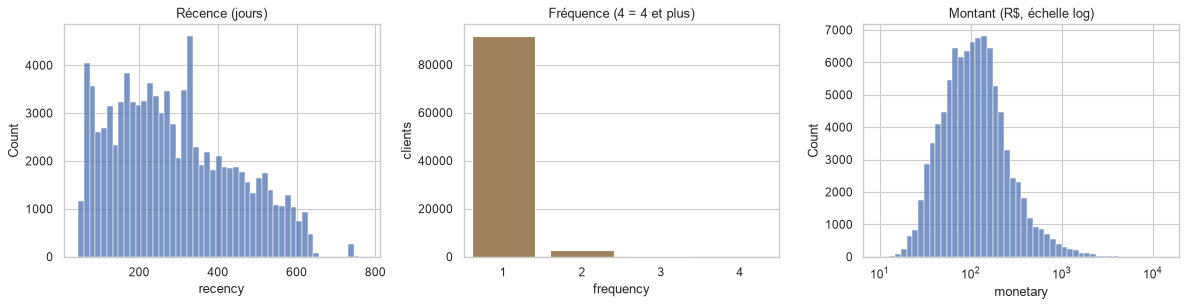

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(rfm["recency"], bins=50, ax=axes[0])
axes[0].set(title="Récence (jours)")
sns.countplot(x=rfm["frequency"].clip(upper=4), color="#AA8350",
              ax=axes[1])
axes[1].set(title="Fréquence (4 = 4 et plus)", ylabel="clients")
sns.histplot(rfm["monetary"], bins=50, log_scale=True, ax=axes[2])
axes[2].set(title="Montant (R$, échelle log)")
plt.tight_layout()
plt.show()

Fréquence et montant sont très asymétriques : on applique un **log** puis une **standardisation** avant K-means, sinon le montant écraserait les deux autres dimensions.

## 2. Choix du nombre de clusters

On teste k de 3 à 7 et on garde celui qui maximise le **score de silhouette** (cohésion interne vs séparation). k = 2 est exclu : il ne fait que séparer les clients revenus des autres, ce qui est trop pauvre pour le marketing.

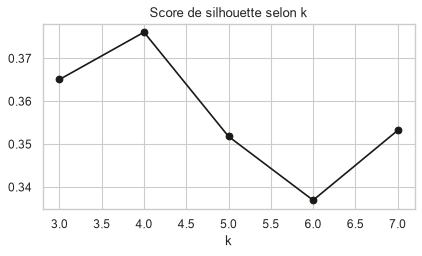

k retenu : 4


In [4]:
segmenter = CustomerSegmenter()
segmented = segmenter.fit_predict(rfm)
silhouettes = pd.Series(segmenter.silhouettes, name="silhouette")
ax = silhouettes.plot(marker="o", figsize=(6, 3), color="#1A1A17")
ax.set(title="Score de silhouette selon k", xlabel="k")
plt.show()
print(f"k retenu : {segmenter.n_clusters}")

## 3. Profil des clusters et personas

Les personas sont attribuées par des règles sur les profils moyens (la plus forte fréquence → fidèles, puis la plus faible récence → nouveaux, puis le plus gros montant → endormis).

In [5]:
profile = CustomerSegmenter.profile(segmented, by="persona")
profile.round(1).sort_values("total_value", ascending=False)

,customers,recency,frequency,monetary,total_value,share_pct,value_share_pct
persona,,,,,,,
Gros acheteurs endormis,28568,335.2,1.0,319.0,9112161.7,30.1,57.9
Nouveaux clients récents,25182,116.9,1.0,122.3,3079213.1,26.5,19.6
Petits acheteurs perdus,38351,367.3,1.0,69.3,2657228.1,40.4,16.9
Fidèles multi-acheteurs,2888,271.4,2.1,308.4,890534.1,3.0,5.7


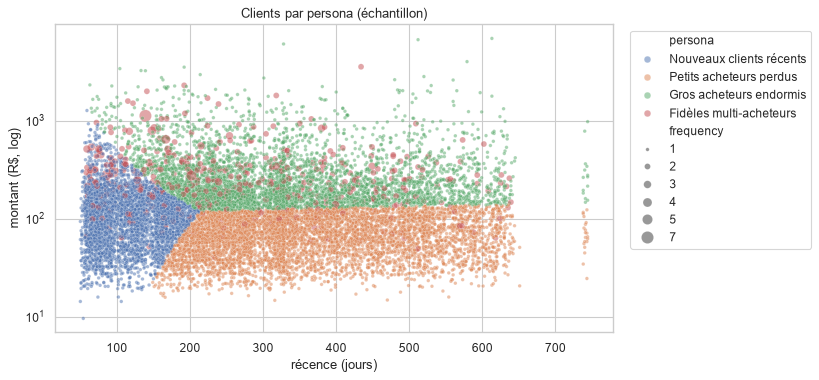

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
sample = segmented.sample(15000, random_state=42)
sns.scatterplot(data=sample, x="recency", y="monetary", hue="persona",
                size="frequency", sizes=(10, 120), alpha=0.5, ax=ax)
ax.set(yscale="log", title="Clients par persona (échantillon)",
       xlabel="récence (jours)", ylabel="montant (R$, log)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

### Les 3 personas ciblées

| Persona | Qui ? | Poids | Enjeu |
|---|---|---|---|
| **Fidèles multi-acheteurs** | ~2 commandes, ~308 R$ dépensés | 3 % des clients, 6 % de la valeur | les garder et les faire racheter plus souvent |
| **Nouveaux clients récents** | 1 commande il y a ~4 mois, ~122 R$ | 27 % des clients, 20 % de la valeur | transformer le 1er achat en 2e |
| **Gros acheteurs endormis** | 1 commande il y a ~11 mois, ~319 R$ | 30 % des clients, **58 % de la valeur** | les faire revenir avant qu'ils ne soient perdus |

Le 4e cluster, **petits acheteurs perdus** (40 % des clients, ~69 R$, dernier achat il y a plus d'un an), n'est **pas ciblé** : le panier est trop faible pour rentabiliser une campagne.

## 4. Trois campagnes chiffrées

Hypothèses (taux de conversion, coût de contact, remise) **à valider par un test A/B** sur un échantillon avant généralisation. Le gain est calculé par rapport au taux de rachat naturel (`baseline_rate`) : on ne compte que les commandes provoquées par la campagne.

In [7]:
simulator = CampaignSimulator(segmented)
pd.DataFrame([vars(campaign) for campaign in simulator.campaigns])

,name,persona,action,contact_cost,conversion_rate,baseline_rate,incentive_rate
0,Club VIP,Fidèles multi-acheteurs,Accès anticipé aux promotions et livraison off...,0.10,0.15,0.05,0.10
1,Relance 2e commande à J+20,Nouveaux clients récents,E-mail + coupon de 10 % envoyé 20 jours après ...,0.05,0.05,0.02,0.10
2,Reconquête des gros paniers,Gros acheteurs endormis,Sélection personnalisée dans leur catégorie + ...,0.05,0.03,0.01,0.12


In [8]:
simulator.summary()

,campagne,persona,clients ciblés,panier moyen (R$),commandes en plus,CA additionnel (R$),coût (R$),gain net (R$),ROI
0,Club VIP,Fidèles multi-acheteurs,2888,145.82,289,42114,6606,35508,5.38
1,Relance 2e commande à J+20,Nouveaux clients récents,25182,122.28,755,92376,16655,75721,4.55
2,Reconquête des gros paniers,Gros acheteurs endormis,28568,318.96,571,182243,34232,148011,4.32


**Lecture** :

1. **Club VIP (fidèles)** : petit segment mais le meilleur ROI (≈ 5 R$ gagnés pour 1 R$ dépensé).
2. **Relance J+20 (nouveaux)** : envoyée juste avant la médiane de 28 jours observée pour la 2e commande (requête SQL 07) ; environ 750 commandes en plus et 76 000 R$ de gain net.
3. **Reconquête (endormis)** : le plus gros gain net (≈ 148 000 R$) car c'est le segment qui pèse le plus en valeur.

**Priorité recommandée** : lancer d'abord la reconquête (gain le plus élevé), avec en parallèle la relance J+20, qui est automatisable.